# Galaxy3 — Experimento 1: CNN propia entrenada desde cero

**Pregunta del bloque:** ¿qué estrategia resulta más adecuada cuando tenemos un conjunto
relativamente pequeño de imágenes astronómicas?

En este notebook construimos la **referencia**: una CNN propia (`GalaxyCNN`) entrenada desde
cero, y observamos sobre la misma arquitectura y el mismo protocolo el cambio asociado a
**BatchNorm** (run A → B) y a **Dropout** (run B → C).

El notebook es un *orquestador pedagógico*: todo el trabajo lo hace el paquete `galaxy3`
(datos, modelo, entrenamiento, métricas, figuras y MLflow). Aquí no hay training loops
propios; el notebook y la CLI (`python -m galaxy3.train`) llaman al mismo
`run_experiment(config)`.

**El conjunto de test no se usa en este notebook.** Se evalúa una sola vez, al final, sobre
la configuración elegida con validation.

| Sección | Tema |
|---|---|
| 0 | Parámetros y ambiente |
| 1 | Pregunta experimental y protocolo |
| 2 | Datos: originales vs transformadas |
| 3 | Batches y shapes |
| 4 | Arquitectura y parámetros |
| 5 | BatchNorm: `train()` vs `eval()` |
| 6 | Dropout: `train()` vs `eval()` |
| 7 | Feature maps antes de entrenar |
| 8 | Qué mostró el piloto y por qué 40 épocas |
| 9 | Los tres runs |
| 10 | Curvas y comparación en validation |
| 11 | Loss vs accuracy: sobreconfianza y errores |
| 12 | MLflow |
| 13 | Feature maps después de entrenar |
| 14 | Cierre |

## 0. Parámetros y ambiente

Esta es la **única celda que cambia** entre una ejecución de prueba y los runs definitivos:

- prueba del notebook: `EPOCHS = 2`, experimento y carpeta de salida de prueba;
- runs definitivos: `EPOCHS = 40` (decisión del piloto, `docs/PILOTO.md`), experimento
  `galaxy3-cnn-from-scratch` y `OUTPUT_ROOT = PROJECT_ROOT / "outputs"`.

In [1]:
from galaxy3.utils import PROJECT_ROOT

EPOCHS = 2  # runs definitivos: 40
EXPERIMENT_NAME = "galaxy3-notebook-dev"  # runs definitivos: "galaxy3-cnn-from-scratch"
# runs definitivos: OUTPUT_ROOT = PROJECT_ROOT / "outputs"
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "notebook_dev"

El ambiente es compartido por todos los experimentos del curso y se llama `mlops_unbosque`
(en la raíz de `Experimentos_MLOPs/`). El intérprete del kernel debe pertenecer a él; si no,
el paquete `galaxy3` instalado no es el del proyecto.

In [2]:
import sys

print(sys.executable)
assert "mlops_unbosque" in sys.executable, "El kernel no usa el ambiente mlops_unbosque"

/home/mauricio/Documents/UnBosque/2026-2/IntroduccionDeepLearning/Experimentos_MLOPs/mlops_unbosque/bin/python3


In [3]:
import json
from dataclasses import replace

import mlflow
import pandas as pd
import torch
from mlflow.tracking import MlflowClient
from torch import nn

from galaxy3.config import ExperimentConfig
from galaxy3.data import (
    build_transform,
    check_stats_match_config,
    load_dataset_stats,
    load_original_samples,
    make_split_loader,
)
from galaxy3.experiment import build_model, resolve_tracking_uri, run_experiment
from galaxy3.inspection import capture_feature_maps
from galaxy3.metrics import collect_predictions, misclassified_indices
from galaxy3.models import count_parameters, count_trainable_parameters
from galaxy3.plots import (
    denormalize,
    plot_confusion_matrix,
    plot_feature_maps,
    plot_image_batch,
    plot_original_galaxies,
    plot_predictions,
    plot_runs_comparison,
    plot_training_curves,
)
from galaxy3.utils import get_device, set_seed

pd.set_option("display.float_format", "{:.4f}".format)

In [4]:
config = ExperimentConfig(
    epochs=EPOCHS,
    mlflow_experiment_name=EXPERIMENT_NAME,
    output_root=OUTPUT_ROOT,
)
device = get_device(config.device_preference)

stats = load_dataset_stats(config.data_root)
check_stats_match_config(stats, config)  # split_seed, image_size y center_crop coinciden
mean, std = stats["mean_train"], stats["std_train"]

print("device:", device)
print("split_seed:", stats["split_seed"], "| train_seed:", config.train_seed)
print("mean_train:", [round(m, 4) for m in mean])
print("std_train: ", [round(s, 4) for s in std])
pd.DataFrame(stats["counts"]).assign(total=lambda df: df.sum(axis=1))

device: cuda
split_seed: 2026 | train_seed: 2026
mean_train: [0.1697, 0.1647, 0.1605]
std_train:  [0.1187, 0.1115, 0.1028]


,train,val,test,total
barred_spiral,1430,307,306,2043
edge_on_no_bulge,996,213,214,1423
round_smooth,1851,397,397,2645


`mean_train` y `std_train` se calcularon **solo con train**, después de `Resize((128, 128))`
y `ToTensor()`. Usar estadísticas de validation o test filtraría información de esos
conjuntos hacia el preprocesamiento.

Hay un desbalance moderado (≈1.9:1 entre `round_smooth` y `edge_on_no_bulge`): por eso
reportamos siempre **macro F1** junto a accuracy.

## 1. Pregunta experimental y protocolo

Tres runs sobre la **misma arquitectura** y el **mismo protocolo**:

| Run | `use_batchnorm` | `dropout_p` | Lectura |
|---|---|---|---|
| A — `baseline` | `False` | 0.0 | referencia |
| B — `batchnorm` | `True` | 0.0 | A → B: cambio asociado a BatchNorm |
| C — `batchnorm_dropout` | `True` | 0.3 | B → C: cambio asociado a Dropout |

No es un diseño factorial completo (falta Dropout sin BN); se acepta por legibilidad.

**Protocolo fijo** (igual para A, B y C):

- `CrossEntropyLoss` sobre logits; `AdamW(lr=1e-3, weight_decay=0.0)`;
- **sin scheduler y sin early stopping**: mezclarlos con Dropout impediría atribuir los
  cambios observados;
- número fijo de épocas: **40**, fijado por el piloto (sección 8);
- se conserva el checkpoint de `argmin val_loss`;
- `train_seed = 2026`, `split_seed = 2026`.

**Decisiones del piloto** (`docs/PILOTO.md`), tomadas antes de ver A, B y C:

| Decisión | Valor |
|---|---|
| `center_crop` | `None` (sin `CenterCrop`) |
| `epochs` | 40 |

**Selección:** métrica primaria fijada de antemano: **macro F1 de validation en la mejor
época** (la de menor `val_loss`). El test no participa en ninguna decisión.

> No diseñamos el problema para que BatchNorm o Dropout "ganen": construimos un problema
> correcto y observamos qué ocurre. "Dropout no produjo una mejora apreciable" es una
> conclusión válida.

## 2. Datos: imágenes originales vs transformadas

Galaxy3 son tres clases de **Galaxy10 DECaLS**: `Round Smooth`, `Barred Spiral` y
`Edge-on without Bulge`, con todas sus imágenes.

Las imágenes **no son fotografías RGB**: son composiciones en **falso color** de tres
bandas fotométricas (g, r, z) asignadas a los canales de la imagen. El color ayuda a ver
la estructura, pero no es el color que vería el ojo.

Primero las originales (256×256), tal como salieron de la preparación, sin ninguna
transformación.

clases (índice = etiqueta): ['barred_spiral', 'edge_on_no_bulge', 'round_smooth']
tamaño original: (256, 256) | modo: RGB


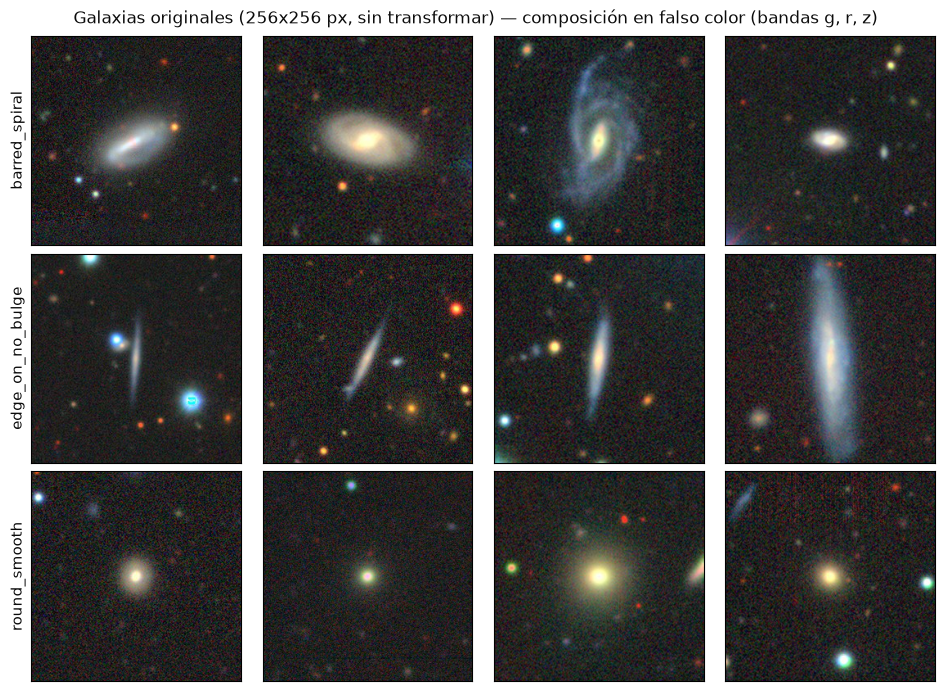

In [5]:
originals = load_original_samples(config.data_root, split="train", per_class=4, seed=0)
class_names = list(originals)
first = next(iter(originals.values()))[0]
print("clases (índice = etiqueta):", class_names)
print("tamaño original:", first.size, "| modo:", first.mode)
plot_original_galaxies(originals);

Ahora **las mismas galaxias** después del pipeline de entrada al modelo:

```text
Resize((128, 128)) -> ToTensor() -> Normalize(mean_train, std_train)
```

Tras `Normalize` los valores ya no están en `[0, 1]`; para mostrarlas hay que
**desnormalizarlas** (`x * std + mean`, y `clamp(0, 1)`). Esa desnormalización es solo para
visualizar: el modelo recibe el tensor normalizado.

tensor transformado: (12, 3, 128, 128) torch.float32
rango normalizado:    [-1.33, 8.16]
rango desnormalizado: [0.01, 1.00]


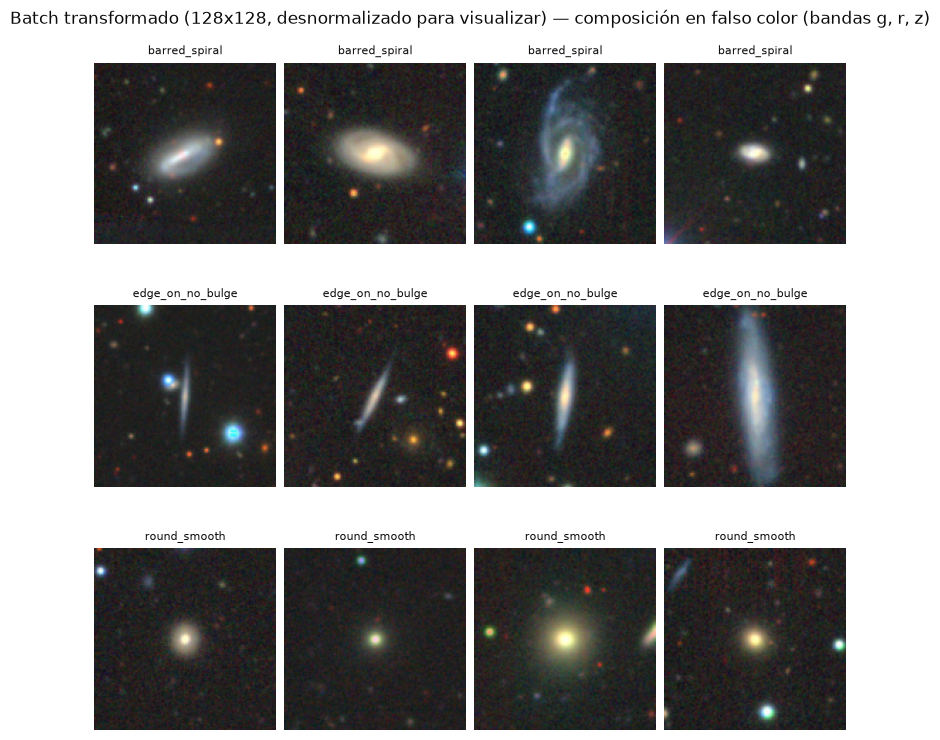

In [6]:
transform = build_transform(config, mean, std)
X_same = torch.stack([transform(img) for imgs in originals.values() for img in imgs])
y_same = torch.tensor([label for label, imgs in enumerate(originals.values()) for _ in imgs])

print("tensor transformado:", tuple(X_same.shape), X_same.dtype)
print(f"rango normalizado:    [{X_same.min():.2f}, {X_same.max():.2f}]")
X_vis = denormalize(X_same, mean, std)
print(f"rango desnormalizado: [{X_vis.min():.2f}, {X_vis.max():.2f}]")
plot_image_batch(X_same, y_same, class_names, mean, std, max_images=12, ncols=4);

## 3. Batches y shapes

Un `DataLoader` agrupa imágenes en batches de forma `B × C × H × W`
(`batch × canales × alto × ancho`) y etiquetas de forma `(B,)` con enteros de clase.

Cada split tiene su propio loader. Aquí construimos **solo train y validation**
(`make_split_loader`): el loader de test no se crea en este notebook.

- train baraja con un `torch.Generator` sembrado con `train_seed`: misma semilla → mismo
  orden de batches;
- validation no baraja: la posición `i` de las predicciones corresponde a
  `val_dataset[i]`.

train: 4277 imágenes, 67 batches
val:   917 imágenes, 15 batches
X: (64, 3, 128, 128) torch.float32 | y: (64,) torch.int64
primeras etiquetas: [2, 0, 0, 2, 0, 2, 1, 0, 1, 1, 2, 2]
media por canal del batch: [0.013267063535749912, 0.014353391714394093, 0.024556083604693413]


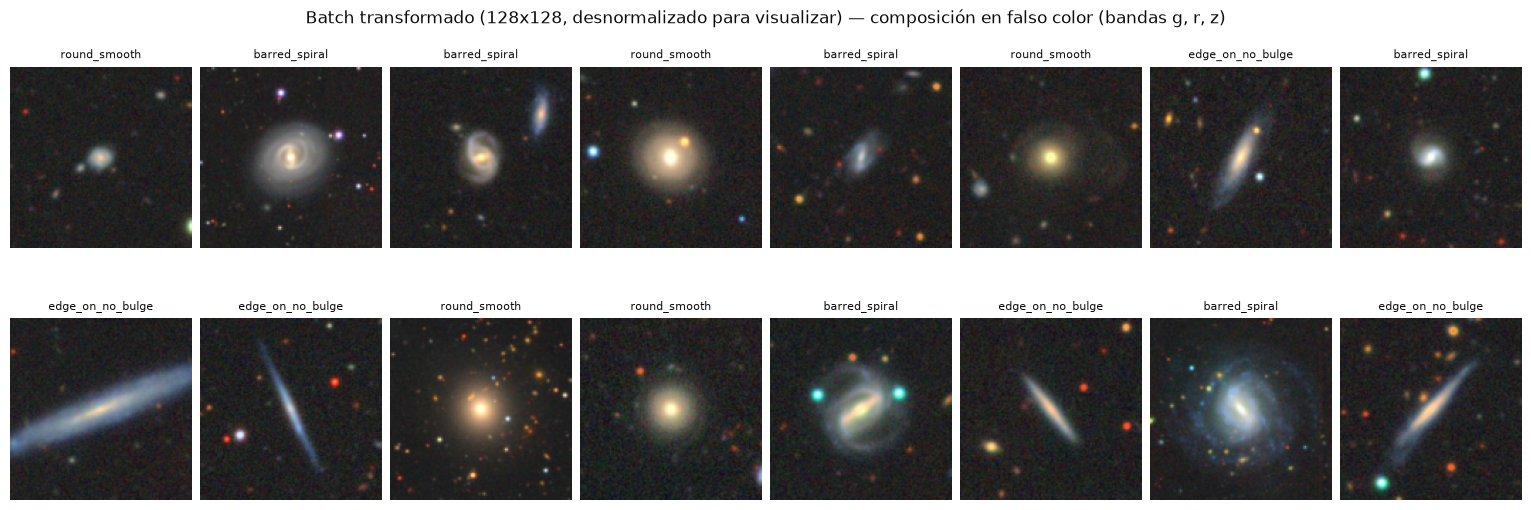

In [7]:
train_loader = make_split_loader(config, "train", device)
val_loader = make_split_loader(config, "val", device)
val_dataset = val_loader.dataset
assert val_dataset.classes == class_names

print("train:", len(train_loader.dataset), "imágenes,", len(train_loader), "batches")
print("val:  ", len(val_dataset), "imágenes,", len(val_loader), "batches")

X, y = next(iter(train_loader))
print("X:", tuple(X.shape), X.dtype, "| y:", tuple(y.shape), y.dtype)
print("primeras etiquetas:", y[:12].tolist())
print("media por canal del batch:", X.mean(dim=(0, 2, 3)).tolist())
plot_image_batch(X, y, class_names, mean, std);

La media por canal del batch normalizado está cerca de 0: `Normalize` centra cada canal con
las estadísticas de train.

## 4. Arquitectura y parámetros

`GalaxyCNN` repite cuatro veces el mismo bloque:

```text
Conv2d(3x3, padding=1) -> BatchNorm2d | Identity -> ReLU -> MaxPool2d(2, 2)
```

- la convolución con `padding=1` conserva el alto y el ancho, y cambia el número de canales
  (3 → 32 → 64 → 128 → 256);
- `MaxPool2d(2, 2)` divide el alto y el ancho por 2;
- `AdaptiveAvgPool2d((2, 2))` lleva cualquier tamaño espacial a 2×2;
- el clasificador aplana (`256·2·2 = 1024`) y aplica `Linear(1024, 128) → ReLU →
  Dropout | Identity → Linear(128, 3)`.

El modelo devuelve **logits** (sin softmax): `CrossEntropyLoss` aplica `log_softmax`
internamente.

Las tres configuraciones son la **misma clase** con otros argumentos. `norm` es
`BatchNorm2d` o `Identity` y `dropout` es `Dropout` o `Identity`, así que los nombres de
las capas no cambian entre A, B y C.

In [11]:
RUNS = {
    "baseline": replace(config, run_name="baseline"),
    "batchnorm": replace(config, run_name="batchnorm", use_batchnorm=True),
    "batchnorm_dropout": replace(
        config, run_name="batchnorm_dropout", use_batchnorm=True, dropout_p=0.3
    ),
}
models = {name: build_model(cfg) for name, cfg in RUNS.items()}
print(models["batchnorm_dropout"])
# Jugar aquí con los keys de RUNS para verificar arquitecturas

GalaxyCNN(
  (features): Sequential(
    (block1): Sequential(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (norm): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (block2): Sequential(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (norm): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (block3): Sequential(
      (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (norm): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): ReLU()
      (pool): MaxPool2d(kernel_size=2, stri

Recorremos las capas con **forward hooks** (`capture_feature_maps`): un hook temporal
registra la salida de una capa interna sin modificar el `forward` del modelo. Así obtenemos
la forma del tensor después de cada bloque.

In [12]:
cpu = torch.device("cpu")
model_a = models["baseline"]
X_small = X[:4]
layers = [
    "features.block1.act",
    "features.block1.pool",
    "features.block2.pool",
    "features.block3.pool",
    "features.block4.act",
    "features.block4.pool",
    "pool",
]
shapes = {"entrada": tuple(X_small.shape)}
shapes |= {name: tuple(capture_feature_maps(model_a, X_small, name, cpu).shape) for name in layers}
model_a.eval()
with torch.inference_mode():
    shapes["logits"] = tuple(model_a(X_small).shape)
pd.Series(shapes, name="shape").to_frame()

,shape
entrada,"(4, 3, 128, 128)"
features.block1.act,"(4, 32, 128, 128)"
features.block1.pool,"(4, 32, 64, 64)"
features.block2.pool,"(4, 64, 32, 32)"
features.block3.pool,"(4, 128, 16, 16)"
features.block4.act,"(4, 256, 16, 16)"
features.block4.pool,"(4, 256, 8, 8)"
pool,"(4, 256, 2, 2)"
logits,"(4, 3)"


In [13]:
def parameter_table(models: dict[str, nn.Module]) -> pd.DataFrame:
    rows = {}
    for name, model in models.items():
        total = count_parameters(model)
        classifier = sum(p.numel() for p in model.classifier.parameters())
        rows[name] = {
            "totales": total,
            "entrenables": count_trainable_parameters(model),
            "clasificador": classifier,
            "% clasificador": 100 * classifier / total,
            "buffers (BN)": sum(b.numel() for b in model.buffers()),
        }
    counts = ["totales", "entrenables", "clasificador", "buffers (BN)"]
    return pd.DataFrame(rows).T.astype(dict.fromkeys(counts, int))


parameter_table(models)

,totales,entrenables,clasificador,% clasificador,buffers (BN)
baseline,520003,520003,131587,25.3050,0
batchnorm,520483,520483,131587,25.2817,964
batchnorm_dropout,520483,520483,131587,25.2817,964


- A tiene **520 003** parámetros y B y C **520 483**: con BatchNorm las convoluciones no
  llevan bias (la β de BN cumple ese papel) y se agregan γ y β por canal
  (`2·(32+64+128+256) = 960`, menos `480` bias quitados).
- Dropout **no agrega parámetros**: B y C tienen exactamente el mismo número.
- El clasificador concentra ≈25 % de los parámetros; el resto está en las convoluciones.
- Los buffers de BN (`running_mean`, `running_var`, `num_batches_tracked`) no son
  parámetros: no reciben gradiente.

## 5. BatchNorm: `train()` vs `eval()`

`BatchNorm2d` normaliza cada canal y luego aplica una escala γ y un desplazamiento β
aprendidos. **Qué media y varianza usa depende del modo**:

- `model.train()`: usa la media y la varianza **del batch actual**, y actualiza las
  *running statistics* (promedio móvil) en los buffers;
- `model.eval()`: usa las **running statistics** acumuladas; la salida de una imagen ya no
  depende de con qué otras imágenes viene en el batch.

Usamos un modelo B recién construido (sin entrenar) para ver el mecanismo.

In [14]:
model_b = build_model(RUNS["batchnorm"])
bn = model_b.features.block1.norm
print("parámetros de BN:", [name for name, _ in bn.named_parameters()])
print("buffers de BN:   ", [name for name, _ in bn.named_buffers()])
print("running_mean[:4] antes:", bn.running_mean[:4].tolist())
print("running_var[:4]  antes:", bn.running_var[:4].tolist())

model_b.train()
with torch.no_grad():
    model_b(X)  # un forward en modo train actualiza las running statistics
print("running_mean[:4] después:", [round(v, 4) for v in bn.running_mean[:4].tolist()])
print("running_var[:4]  después:", [round(v, 4) for v in bn.running_var[:4].tolist()])
print("num_batches_tracked:", int(bn.num_batches_tracked))

parámetros de BN: ['weight', 'bias']
buffers de BN:    ['running_mean', 'running_var', 'num_batches_tracked']
running_mean[:4] antes: [0.0, 0.0, 0.0, 0.0]
running_var[:4]  antes: [1.0, 1.0, 1.0, 1.0]
running_mean[:4] después: [-0.0002, 0.0008, -0.0007, 0.0006]
running_var[:4]  después: [0.904, 0.9125, 0.9238, 0.9107]
num_batches_tracked: 1


Ahora la misma imagen (la primera del batch) dentro de dos batches distintos: uno de 16
imágenes y otro de 4.

In [15]:
def first_logits(model: nn.Module, batch: torch.Tensor) -> torch.Tensor:
    with torch.no_grad():
        return model(batch)[0]


model_b.train()
train_16, train_4 = first_logits(model_b, X[:16]), first_logits(model_b, X[:4])
model_b.eval()
eval_16, eval_4 = first_logits(model_b, X[:16]), first_logits(model_b, X[:4])

pd.DataFrame(
    {
        "batch de 16": [train_16.tolist(), eval_16.tolist()],
        "batch de 4": [train_4.tolist(), eval_4.tolist()],
        "iguales": [torch.allclose(train_16, train_4), torch.allclose(eval_16, eval_4, atol=1e-6)],
    },
    index=["train()", "eval()"],
)

,batch de 16,batch de 4,iguales
train(),"[0.1314070224761963, 0.010357201099395752, 0.0...","[0.15284386277198792, 0.0357603020966053, 0.03...",False
eval(),"[-0.05198321491479874, 0.022305164486169815, 0...","[-0.051983218640089035, 0.022305166348814964, ...",True


En `train()` los logits de la misma imagen cambian según el batch (la normalización usa
estadísticas del batch). En `eval()` son iguales. Por eso la evaluación siempre se hace en
modo eval, y por eso el *generalization gap* se calcula evaluando train **también en modo
eval** con el best checkpoint (no con el `train_acc` acumulado durante el entrenamiento).

Ojo: en los forwards en modo `train()` de esta celda también se actualizaron las running
statistics. Es un modelo de demostración; no se usa para nada más.

## 6. Dropout: `train()` vs `eval()`

`Dropout(p)` pone en cero cada activación con probabilidad `p` durante el entrenamiento y
escala las que sobreviven por `1/(1-p)`, para que el valor esperado no cambie. En
`eval()` no hace nada.

Primero la capa sola, sobre un tensor de unos:

In [16]:
model_c = build_model(RUNS["batchnorm_dropout"])
dropout = model_c.classifier.dropout
print(dropout)

set_seed(0)
ones = torch.ones(1, 12)
dropout.train()
print("train():", dropout(ones))
dropout.eval()
print("eval(): ", dropout(ones))
print("1 / (1 - p) =", round(1 / (1 - dropout.p), 4))

Dropout(p=0.3, inplace=False)
train(): tensor([[0.0000, 0.0000, 1.4286, 0.0000, 1.4286, 0.0000, 1.4286, 1.4286, 1.4286,
         1.4286, 1.4286, 1.4286]])
eval():  tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])
1 / (1 - p) = 1.4286


Ahora el modelo C completo: dos forwards seguidos del mismo batch.

In [18]:
with torch.no_grad():
    model_c.train()
    train_1, train_2 = model_c(X[:4]), model_c(X[:4])
    model_c.eval()
    eval_1, eval_2 = model_c(X[:4]), model_c(X[:4])

print("train(): dos forwards iguales?", torch.allclose(train_1, train_2))
print("eval():  dos forwards iguales?", torch.equal(eval_1, eval_2))

train(): dos forwards iguales? False
eval():  dos forwards iguales? True


En `train()` cada forward usa una máscara distinta (la máscara consume el RNG global; por
eso `train_seed` también controla Dropout). En `eval()` la salida es determinista.

En C, BN está en modo train en ambos forwards con el mismo batch, así que la diferencia
entre `train_1` y `train_2` viene solo de Dropout.

## 7. Feature maps antes de entrenar

Un **feature map** es la salida de una capa convolucional para un canal: un mapa 2D que
indica dónde y con qué intensidad responde ese filtro. Los capturamos con un forward hook
temporal (`capture_feature_maps`), que se retira siempre, incluso si hay un error.

Usamos el modelo A **sin entrenar**, construido con la misma semilla que usa
`run_experiment` justo antes de construir el modelo; por eso sus pesos son los pesos
iniciales del run A. Elegimos una galaxia fija de validation y dos profundidades:

- `features.block1.act`: salida de la ReLU del bloque 1, `(32, 128, 128)`;
- `features.block3.act`: salida de la ReLU del bloque 3, `(128, 32, 32)`.

Visualización: escala de grises con **normalización por mapa** (el brillo solo se compara
dentro de un mismo mapa). Un mapa constante (por ejemplo, una ReLU apagada en toda la
imagen) se marca como "constante".

No asignamos significado a canales individuales: los feature maps sirven para ver cómo
cambia la representación con la profundidad y con el entrenamiento, no para afirmar que un
canal "detecta" una estructura astronómica.

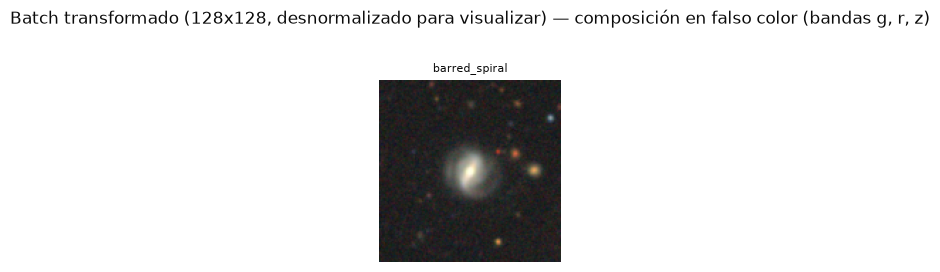

In [19]:
SAMPLE_INDEX = 0  # posición en val_dataset (fija para comparar antes y después)
FM_LAYERS = ["features.block1.act", "features.block3.act"]

x_sample, y_sample = val_dataset[SAMPLE_INDEX]
x_sample = x_sample.unsqueeze(0)
plot_image_batch(x_sample, torch.tensor([y_sample]), class_names, mean, std, ncols=1);

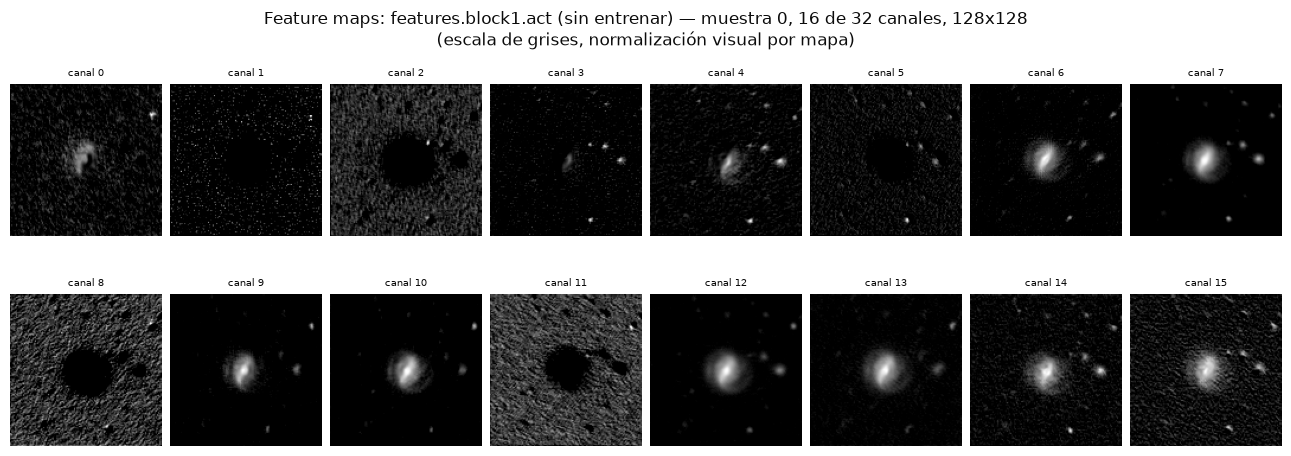

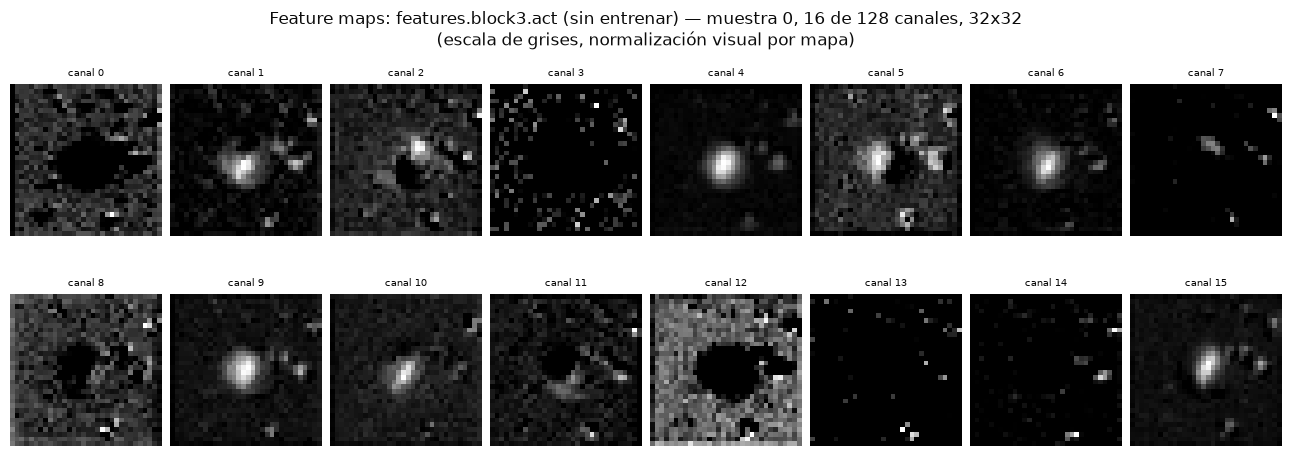

In [20]:
set_seed(config.train_seed)
untrained_a = build_model(RUNS["baseline"])

maps_before = {
    layer: capture_feature_maps(untrained_a, x_sample, layer, cpu) for layer in FM_LAYERS
}
for layer, maps in maps_before.items():
    plot_feature_maps(maps, layer_name=f"{layer} (sin entrenar)")

Con pesos aleatorios los mapas ya "responden" a la imagen: una convolución con pesos al
azar sigue siendo un filtro local, que realza bordes y zonas brillantes. Pero no hay nada
aprendido. En el bloque 3 la resolución es menor (32×32) y cada posición resume una región
más grande de la imagen.

## 8. Qué mostró el piloto y por qué 40 épocas

Antes de los runs definitivos se entrenó **solo el baseline (A) durante 50 épocas**, en un
experimento MLflow separado (`galaxy3-pilot`), usando únicamente train y validation. El
objetivo era ver dónde converge `val_loss` y fijar un presupuesto de épocas común para A, B
y C. El piloto **no** se usó para elegir entre A, B y C.

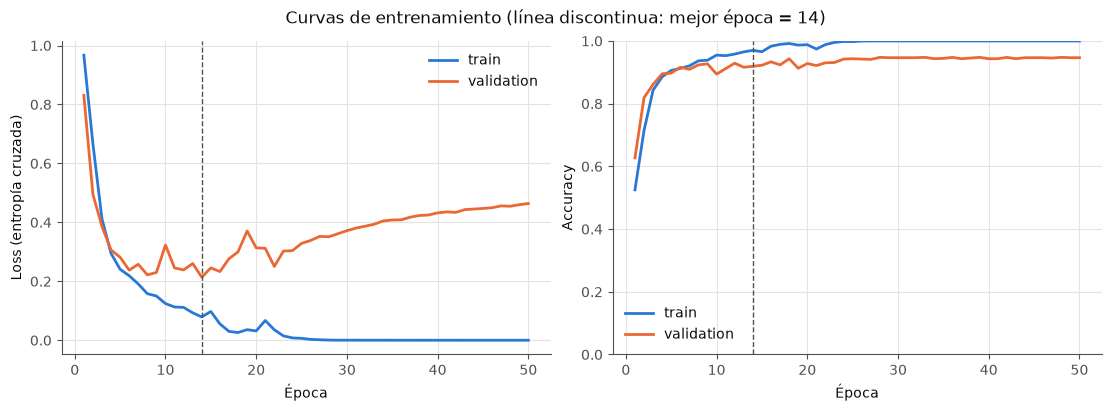

In [21]:
pilot = json.loads((PROJECT_ROOT / "outputs" / "metrics" / "pilot_baseline.json").read_text())
pilot_history = pilot["history"]
plot_training_curves(pilot_history);

In [22]:
pilot_epochs = [pilot_history["best_epoch"], 20, 25, 30, 40, 50]
pd.DataFrame(
    {
        key: [pilot_history[key][e - 1] for e in pilot_epochs]
        for key in ("val_loss", "val_acc", "train_loss", "train_acc")
    },
    index=pd.Index(pilot_epochs, name="época"),
).T

época,14,20,25,30,40,50
val_loss,0.2140,0.3135,0.3287,0.3718,0.4321,0.4639
val_acc,0.9193,0.9280,0.9433,0.9466,0.9433,0.9466
train_loss,0.0792,0.0317,0.0065,0.0003,0.0001,0.0000
train_acc,0.9701,0.9881,0.9979,1.0000,1.0000,1.0000


- El mínimo de `val_loss` está en la **época 14**. Desde la época ≈22, `val_loss` sube de
  forma casi monótona hasta más del doble de su mínimo, y desde la 27 `train_acc = 1.0`: el
  modelo memoriza train.
- **Decisión: 40 épocas** para A, B y C. 40 ≈ 2.9 × 14 deja ver el sobreajuste completo en
  A, y deja margen si BatchNorm o Dropout desplazan el mínimo hasta las épocas 20–25. Más
  allá de la 30, A solo prolonga la misma tendencia; cada run cuesta ≈ 2 minutos en la
  RTX 3060.

Hay algo raro en la tabla: **`val_loss` sube pero `val_acc` no baja**. Volveremos sobre esto
en la sección 11, con nuestro propio run A.

## 9. Los tres runs

Cada run es una llamada a `run_experiment(config)`, la misma función que usa la CLI:

```bash
uv run python -m galaxy3.train --run-name batchnorm --use-batchnorm --epochs 40
```

Dentro de `run_experiment`: siembra `train_seed` → construye los loaders de train y val →
construye el modelo → entrena `epochs` épocas con `fit` (guardando el checkpoint de menor
`val_loss`) → recarga ese checkpoint → evalúa train y val **en modo eval** → calcula métricas
y figuras → registra todo en MLflow. **No toca test.**

Los runs se ejecutan **en serie**, para que los tiempos por época sean comparables. (Como
procesos independientes también podrían lanzarse en paralelo desde varias terminales.)

In [23]:
print(f"EPOCHS = {EPOCHS} | experimento MLflow: {EXPERIMENT_NAME} | salida: {OUTPUT_ROOT}")
results = {}
for name, run_config in RUNS.items():
    print(f"\n=== {name} ===")
    results[name] = run_experiment(run_config)

EPOCHS = 2 | experimento MLflow: galaxy3-notebook-dev | salida: /home/mauricio/Documents/UnBosque/2026-2/IntroduccionDeepLearning/Experimentos_MLOPs/galaxy3/outputs/notebook_dev

=== baseline ===
Época   1/2 | train loss 0.9676 acc 0.5233 | val loss 0.8409 acc 0.6260 | 3.2s *
Época   2/2 | train loss 0.6553 acc 0.7211 | val loss 0.4942 acc 0.8113 | 2.7s *

=== batchnorm ===
Época   1/2 | train loss 0.6945 acc 0.7068 | val loss 0.5324 acc 0.7906 | 3.0s *
Época   2/2 | train loss 0.3852 acc 0.8555 | val loss 0.4906 acc 0.8212 | 2.7s *

=== batchnorm_dropout ===
Época   1/2 | train loss 0.7266 acc 0.6904 | val loss 0.5463 acc 0.7961 | 3.0s *
Época   2/2 | train loss 0.4010 acc 0.8515 | val loss 0.3235 acc 0.8713 | 2.8s *


In [24]:
summary = pd.DataFrame({name: result.final_metrics() for name, result in results.items()}).T
summary["best_epoch"] = summary["best_epoch"].astype(int)
summary["s/época"] = [
    sum(r.history["epoch_time"]) / len(r.history["epoch_time"]) for r in results.values()
]
summary

,best_epoch,best_val_loss,train_loss_eval,train_acc_eval,val_acc_best,val_macro_f1,generalization_gap,s/época
baseline,2,0.4942,0.4780,0.8059,0.8113,0.7977,-0.0054,2.9127
batchnorm,2,0.4906,0.4764,0.8193,0.8212,0.8336,-0.0019,2.8928
batchnorm_dropout,2,0.3235,0.3172,0.8735,0.8713,0.8717,0.0022,2.8692


## 10. Curvas y comparación en validation

Cómo leer las curvas de cada run:

- **`train_*`** se acumula durante la época en modo train (con Dropout activo, BN con
  estadísticas del batch y pesos que cambian dentro de la época); **`val_*`** se mide al
  final de la época en modo eval. Por eso no son directamente comparables punto a punto.
- La línea discontinua marca la **mejor época** (mínimo de `val_loss`): es el checkpoint que
  se conserva.
- Si `val_loss` sube después del mínimo mientras `train_loss` sigue bajando, el modelo
  sobreajusta.

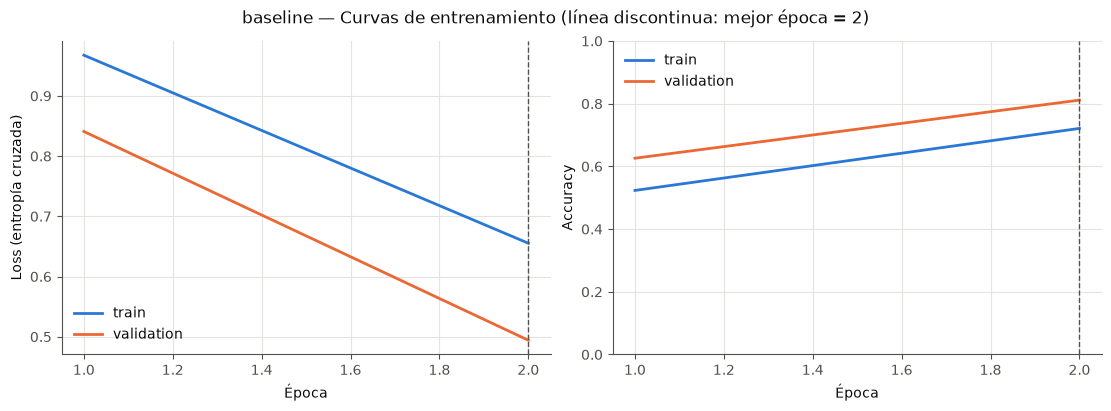

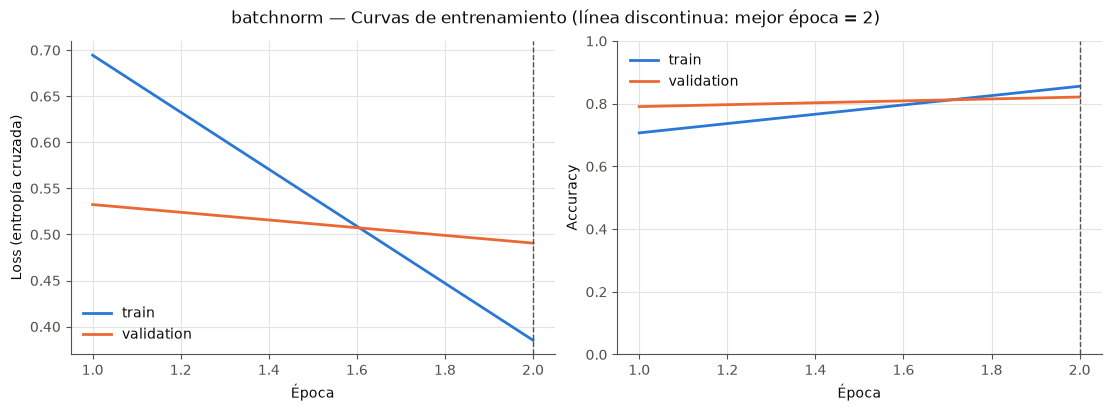

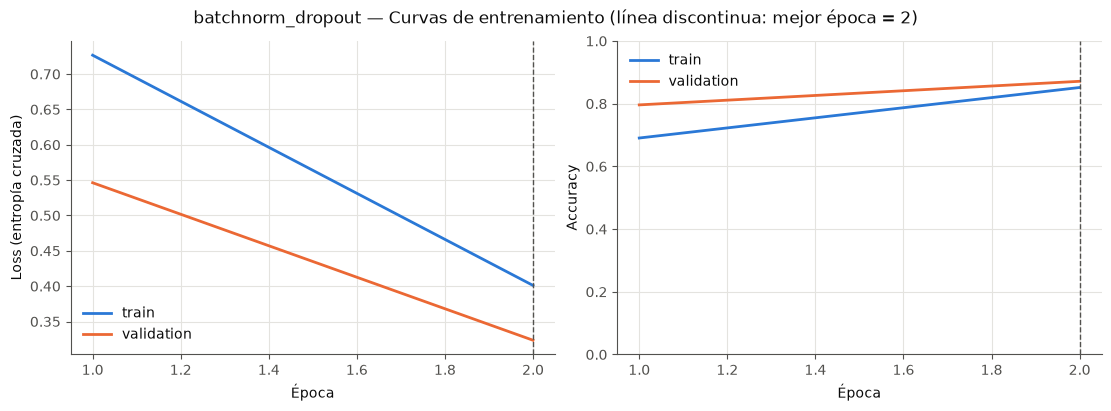

In [25]:
for name, result in results.items():
    fig = plot_training_curves(result.history)
    fig.suptitle(f"{name} — {fig.get_suptitle()}")

Las tres historias de validation superpuestas. Cada run tiene un color y un estilo de
línea fijos (continua, discontinua, punteada), así que se distinguen también en escala de
grises. El marcador indica la mejor época de cada run; en el panel de accuracy marca la
`val_acc` del checkpoint conservado, que no tiene por qué ser el máximo de `val_acc`.

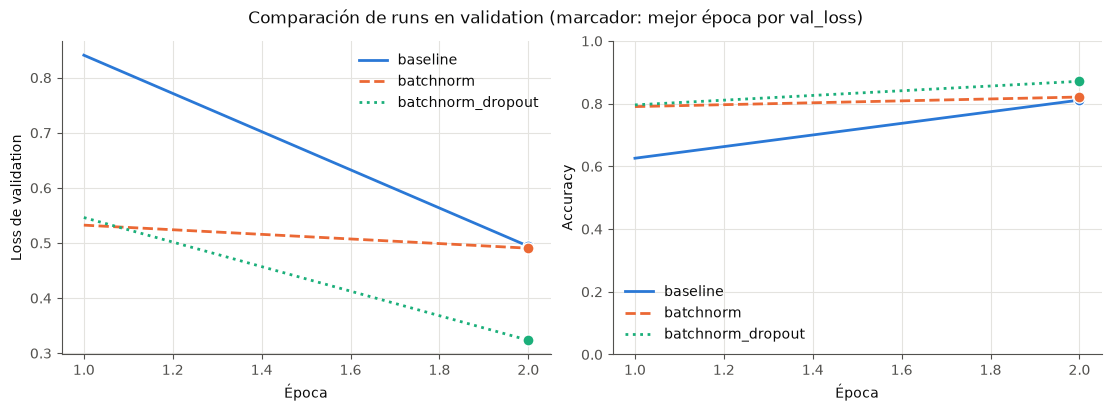

In [26]:
plot_runs_comparison({name: result.history for name, result in results.items()});

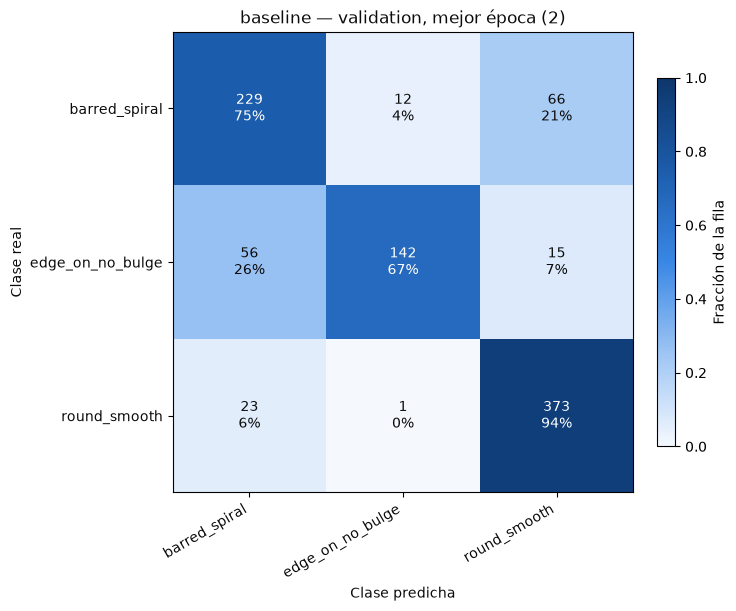

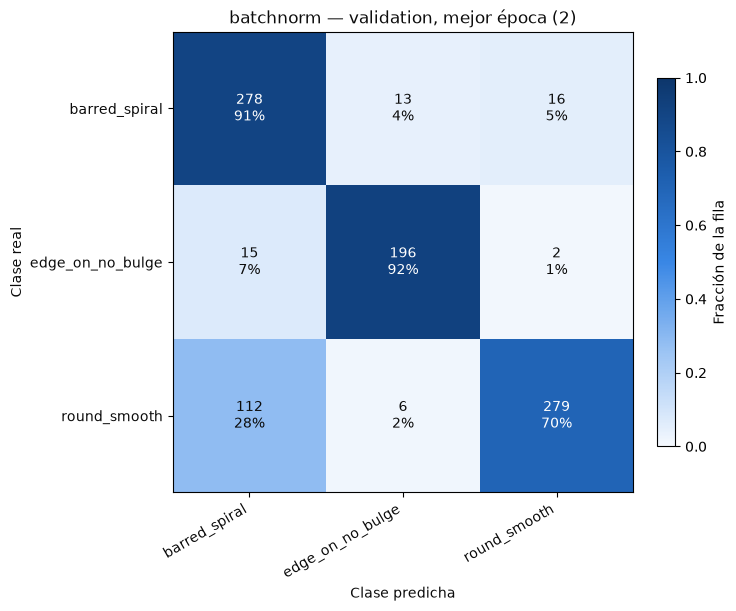

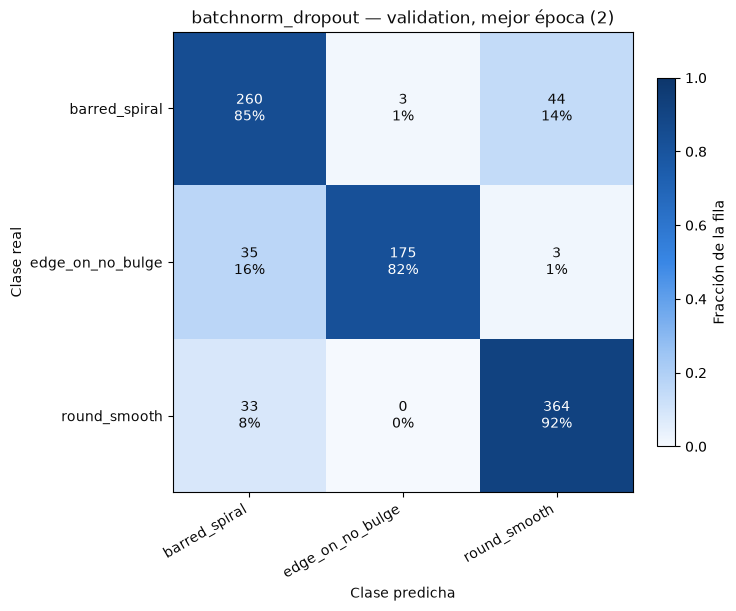

In [27]:
for name, result in results.items():
    plot_confusion_matrix(
        result.val_eval.report.confusion_matrix,
        class_names,
        title=f"{name} — validation, mejor época ({result.history['best_epoch']})",
    )

In [28]:
def comparison_row(result) -> dict[str, float]:
    h = result.history
    best = h["best_epoch"]
    return {
        "best_epoch": best,
        "val_loss (mejor)": h["best_val_loss"],
        "val_loss (última)": h["val_loss"][-1],
        "val_acc (mejor)": result.val_eval.report.accuracy,
        "val_acc (máx.)": max(h["val_acc"]),
        "val_macro_f1": result.val_eval.report.macro_f1,
        "train_acc_eval": result.train_eval.report.accuracy,
        "gap": result.generalization_gap,
    }


comparison = pd.DataFrame({name: comparison_row(r) for name, r in results.items()}).T
comparison["best_epoch"] = comparison["best_epoch"].astype(int)
comparison

,best_epoch,val_loss (mejor),val_loss (última),val_acc (mejor),val_acc (máx.),val_macro_f1,train_acc_eval,gap
baseline,2,0.4942,0.4942,0.8113,0.8113,0.7977,0.8059,-0.0054
batchnorm,2,0.4906,0.4906,0.8212,0.8212,0.8336,0.8193,-0.0019
batchnorm_dropout,2,0.3235,0.3235,0.8713,0.8713,0.8717,0.8735,0.0022


In [29]:
selected = comparison["val_macro_f1"].idxmax()
n_val = results[selected].val_samples
print(f"Configuración seleccionada (macro F1 de validation): {selected}")
print(f"Con {n_val} imágenes de validation, 1 punto de accuracy ≈ {n_val / 100:.0f} imágenes.")

Configuración seleccionada (macro F1 de validation): batchnorm_dropout
Con 917 imágenes de validation, 1 punto de accuracy ≈ 9 imágenes.


**Cómo interpretar la tabla**

- `gap = train_acc_eval − val_acc`, ambos en modo eval con el best checkpoint.
- Comparamos con **una sola `train_seed`**: las diferencias son descriptivas, no evidencia
  estadística. Una diferencia de un punto son ≈9 imágenes de validation.
- La selección usa la métrica primaria fijada antes de correr (macro F1 de validation en la
  mejor época). El test no participa.
- Fíjense en el run A: `val_loss (última)` frente a `val_loss (mejor)`, y `val_acc (máx.)`
  frente a `val_acc (mejor)`. Es la misma paradoja del piloto.

## 11. Loss vs accuracy: sobreconfianza y errores

**La paradoja.** En el run A (y en el piloto), después de la mejor época `val_loss` sube con
fuerza, pero `val_acc` se mantiene o incluso mejora. ¿Cómo puede empeorar la loss si el
modelo no se equivoca más?

**La clave: qué mide cada una.** Para una imagen con clase real `c`, la entropía cruzada es

$$\ell = -\log p_c, \qquad p = \mathrm{softmax}(\text{logits}).$$

- La **accuracy** solo mira si `argmax p` es la clase real: no distingue un acierto con
  `p_c = 0.51` de uno con `p_c = 0.99`, ni un error dudoso de uno seguro.
- La **loss** mira la probabilidad asignada a la clase real. Un acierto confiado cuesta casi
  0, pero un **error confiado** cuesta mucho: con `p_c = 0.01`, `ℓ = 4.6`; con
  `p_c = 0.0001`, `ℓ = 9.2`. La loss no tiene techo.

Ejemplo de juguete: dos modelos con **las mismas predicciones** (mismo `argmax`, misma
accuracy) sobre tres imágenes de clase real 0.

In [30]:
y_toy = torch.tensor([0, 0, 0])
toy_logits = {
    "prudente": torch.tensor([[2.0, 0.0, 0.0], [1.5, 0.5, 0.0], [0.0, 0.8, 0.0]]),
    "sobreconfiado": torch.tensor([[9.0, 0.0, 0.0], [8.0, 0.0, 0.0], [0.0, 9.0, 0.0]]),
}
per_sample_loss = nn.CrossEntropyLoss(reduction="none")

rows = {}
for name, logits in toy_logits.items():
    losses = per_sample_loss(logits, y_toy)
    rows[name] = {
        "pred": logits.argmax(dim=1).tolist(),
        "p(clase real)": [round(p, 4) for p in torch.softmax(logits, dim=1)[:, 0].tolist()],
        "loss por imagen": [round(v, 3) for v in losses.tolist()],
        "accuracy": (logits.argmax(dim=1) == y_toy).float().mean().item(),
        "loss media": losses.mean().item(),
    }
pd.DataFrame(rows).T

,pred,p(clase real),loss por imagen,accuracy,loss media
prudente,"[0, 0, 1]","[0.787, 0.6285, 0.2367]","[0.24, 0.464, 1.441]",0.6667,0.7150
sobreconfiado,"[0, 0, 1]","[0.9998, 0.9993, 0.0001]","[0.0, 0.001, 9.0]",0.6667,3.0004


Ambos aciertan 2 de 3. El sobreconfiado tiene una loss media mucho mayor, y casi toda viene
de su **único error**, cometido con mucha seguridad.

Eso es lo que pasa después de la mejor época: el modelo sigue empujando los logits de train
hacia `train_loss → 0` y se vuelve más seguro **en todo**, también en los errores que todavía
comete en validation. `val_acc` no cambia (los errores son casi los mismos), pero cada error
pesa más en `val_loss`.

**Consecuencia para el protocolo.** Elegimos el checkpoint por `argmin val_loss` (fijado de
antemano): es el modelo que asigna **mejores probabilidades** a la clase real (menor
entropía cruzada en validation), no el de mayor accuracy. En el piloto eso
significó ≈2.7 puntos menos de `val_acc` que en épocas tardías. No cambiamos el criterio a
posteriori; lo discutimos.

### Lo mismo en nuestros runs

Recargamos el best checkpoint de cada run **explícitamente** con
`torch.load(..., weights_only=True)`: el archivo solo contiene tensores, `state_dict` y tipos
primitivos, así que no hace falta (ni conviene) permitir objetos arbitrarios de Python.

In [31]:
def load_best_model(result) -> tuple[nn.Module, dict]:
    checkpoint = torch.load(result.checkpoint_path, map_location=device, weights_only=True)
    model = build_model(result.config).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    return model, checkpoint


best_models = {}
for name, result in results.items():
    best_models[name], checkpoint = load_best_model(result)
    print(
        f"{name}: época {checkpoint['epoch']}, val_loss {checkpoint['val_loss']:.4f}, "
        f"claves {sorted(checkpoint)}"
    )

baseline: época 2, val_loss 0.4942, claves ['config', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'val_loss']
batchnorm: época 2, val_loss 0.4906, claves ['config', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'val_loss']
batchnorm_dropout: época 2, val_loss 0.3235, claves ['config', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'val_loss']


Con `collect_predictions` (modo eval, mismo bucle que `engine.evaluate`) obtenemos las
probabilidades de validation y separamos `−log p(clase real)` entre aciertos y errores.

In [32]:
loss_fn = nn.CrossEntropyLoss()
val_predictions = {
    name: collect_predictions(model, val_loader, loss_fn, device)
    for name, model in best_models.items()
}


def loss_breakdown(pred) -> dict[str, float]:
    p_true = pred.probabilities[torch.arange(len(pred.y_true)), pred.y_true]
    nll = -torch.log(p_true.clamp_min(torch.finfo(p_true.dtype).tiny))
    wrong = pred.y_pred != pred.y_true
    return {
        "val_loss": pred.loss,
        "val_acc": pred.accuracy,
        "errores": int(wrong.sum()),
        "−log p media (aciertos)": nll[~wrong].mean().item(),
        "−log p media (errores)": nll[wrong].mean().item() if wrong.any() else float("nan"),
        "% de la loss por errores": 100 * nll[wrong].sum().item() / nll.sum().item(),
        "confianza media en errores": pred.probabilities[wrong].max(dim=1).values.mean().item()
        if wrong.any()
        else float("nan"),
    }


breakdown = pd.DataFrame({name: loss_breakdown(p) for name, p in val_predictions.items()}).T
breakdown.astype({"errores": int})

,val_loss,val_acc,errores,−log p media (aciertos),−log p media (errores),% de la loss por errores,confianza media en errores
baseline,0.4942,0.8113,173,0.1888,1.8073,68.9998,0.6466
batchnorm,0.4906,0.8212,164,0.1560,2.0268,73.8839,0.7154
batchnorm_dropout,0.3235,0.8713,118,0.1361,1.5928,63.3555,0.6992


Los errores son pocos, pero aportan una fracción grande de la loss: cada uno cuesta mucho
más que un acierto. Este desglose es en la **mejor época**; después de ella, la confianza en
esos errores sigue creciendo y `val_loss` sube aunque `val_acc` no cambie.

### Errores de la configuración seleccionada

Las imágenes de validation peor clasificadas por el run seleccionado, ordenadas de mayor a
menor confianza en el error. Las probabilidades salen de un softmax aplicado solo para el
análisis; el modelo sigue devolviendo logits.

batchnorm_dropout: 118 errores en 917 imágenes


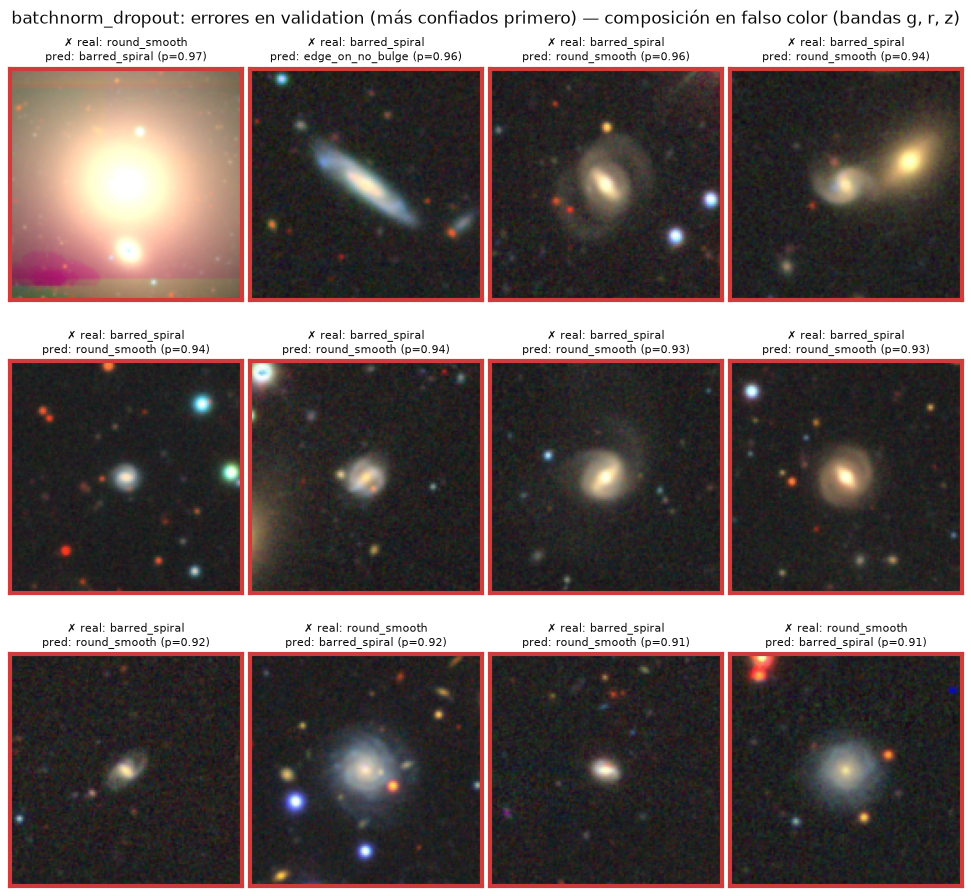

In [33]:
pred = val_predictions[selected]
error_idx = misclassified_indices(pred, max_count=12)
print(
    f"{selected}: {int((pred.y_pred != pred.y_true).sum())} errores en {len(pred.y_true)} imágenes"
)
if len(error_idx) > 0:
    X_errors = torch.stack([val_dataset[int(i)][0] for i in error_idx])
    plot_predictions(
        X_errors,
        pred.y_true[error_idx],
        pred.probabilities[error_idx],
        class_names,
        mean,
        std,
        title=f"{selected}: errores en validation (más confiados primero)",
    )

Preguntas para discutir: ¿entre qué clases se concentran los errores (ver las matrices de
confusión de la sección 10)? ¿Hay imágenes ambiguas incluso para un humano: galaxias pequeñas,
con poca señal o con estrellas cercanas? ¿Con qué confianza se equivoca el modelo?

## 12. MLflow

MLflow guarda, para cada run: los **parámetros** (configuración, device, número de
parámetros, tamaños de los splits), las **métricas por época** (`step = epoch`), las
**métricas finales** y los **artifacts** (config, best checkpoint, curvas, tabla de métricas).
Las figuras las construye `plots.py` con Matplotlib; `experiment.py` las registra.

El backend local es una base SQLite dentro de `galaxy3/` (o `MLFLOW_TRACKING_URI` si está
definida).

In [34]:
tracking_uri = resolve_tracking_uri()
mlflow.set_tracking_uri(tracking_uri)
print("tracking URI:", tracking_uri)

run_ids = [result.run_id for result in results.values()]
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])
columns = [
    "tags.mlflow.runName",
    "run_id",
    "status",
    "params.use_batchnorm",
    "params.dropout_p",
    "params.epochs",
    "metrics.best_epoch",
    "metrics.val_acc_best",
    "metrics.val_macro_f1",
    "metrics.generalization_gap",
]
runs[runs["run_id"].isin(run_ids)][columns]

tracking URI: sqlite:////home/mauricio/Documents/UnBosque/2026-2/IntroduccionDeepLearning/Experimentos_MLOPs/galaxy3/mlflow.db


,tags.mlflow.runName,run_id,status,params.use_batchnorm,params.dropout_p,params.epochs,metrics.best_epoch,metrics.val_acc_best,metrics.val_macro_f1,metrics.generalization_gap
0,batchnorm_dropout,37ff0e0867ff47e8bec848d989bc007e,FINISHED,True,0.3,2,2.0000,0.8713,0.8717,0.0022
1,batchnorm,fa9fd2ab538d4649ae8a5cd10956bade,FINISHED,True,0.0,2,2.0000,0.8212,0.8336,-0.0019
2,baseline,bfa936f7672141179fe556058c769a1e,FINISHED,False,0.0,2,2.0000,0.8113,0.7977,-0.0054


In [35]:
client = MlflowClient()
example_run = results[selected].run_id
print("artifacts del run", selected)
for artifact in client.list_artifacts(example_run):
    print("  ", artifact.path, "(carpeta)" if artifact.is_dir else "")

artifacts del run batchnorm_dropout
   checkpoints (carpeta)
   config.json 
   figures (carpeta)
   metrics (carpeta)


La historia por época también se puede recuperar desde MLflow. Por ejemplo, `val_loss` del
piloto (experimento `galaxy3-pilot`), que debe coincidir con la del JSON de la sección 8:

In [36]:
pilot_val_loss = (
    pd.DataFrame(
        [(m.step, m.value) for m in client.get_metric_history(pilot["run_id"], "val_loss")],
        columns=["época", "val_loss"],
    )
    .sort_values("época")
    .set_index("época")
)
assert len(pilot_val_loss) == len(pilot_history["val_loss"])
pilot_val_loss.T

época,1,2,3,4,5,6,7,8,9,10,...,41,42,43,44,45,46,47,48,49,50
val_loss,0.8309,0.4948,0.3859,0.3064,0.2816,0.2380,0.2577,0.2219,0.2299,0.3232,...,0.4357,0.4338,0.4433,0.4451,0.4472,0.4496,0.4559,0.4547,0.4599,0.4639


Para comparar los runs gráficamente, abrir la interfaz de MLflow desde una terminal en la
raíz del workspace (y luego <http://127.0.0.1:5000>):

In [37]:
print(f"uv run mlflow ui --backend-store-uri {tracking_uri}")

uv run mlflow ui --backend-store-uri sqlite:////home/mauricio/Documents/UnBosque/2026-2/IntroduccionDeepLearning/Experimentos_MLOPs/galaxy3/mlflow.db


## 13. Feature maps después de entrenar

La misma galaxia, las mismas capas y el **mismo modelo A**, ahora con los pesos del best
checkpoint. Como el modelo sin entrenar de la sección 7 tenía los pesos iniciales del run A,
la única diferencia es el entrenamiento.

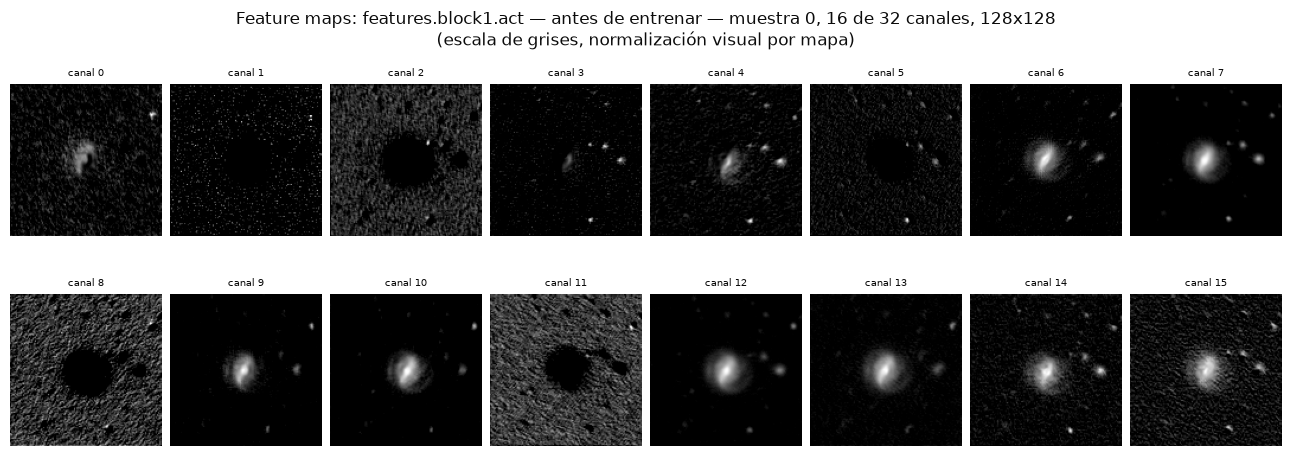

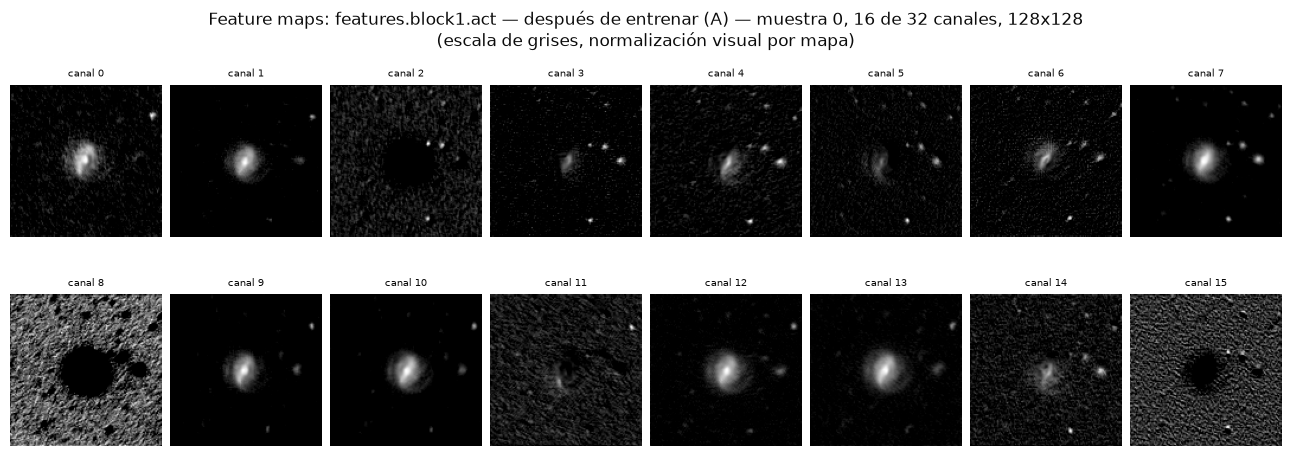

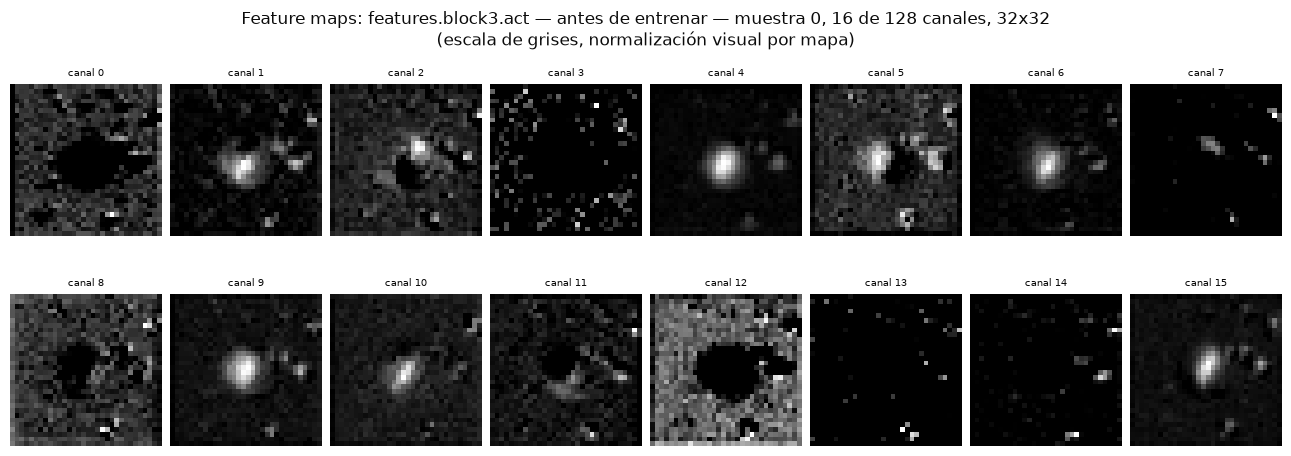

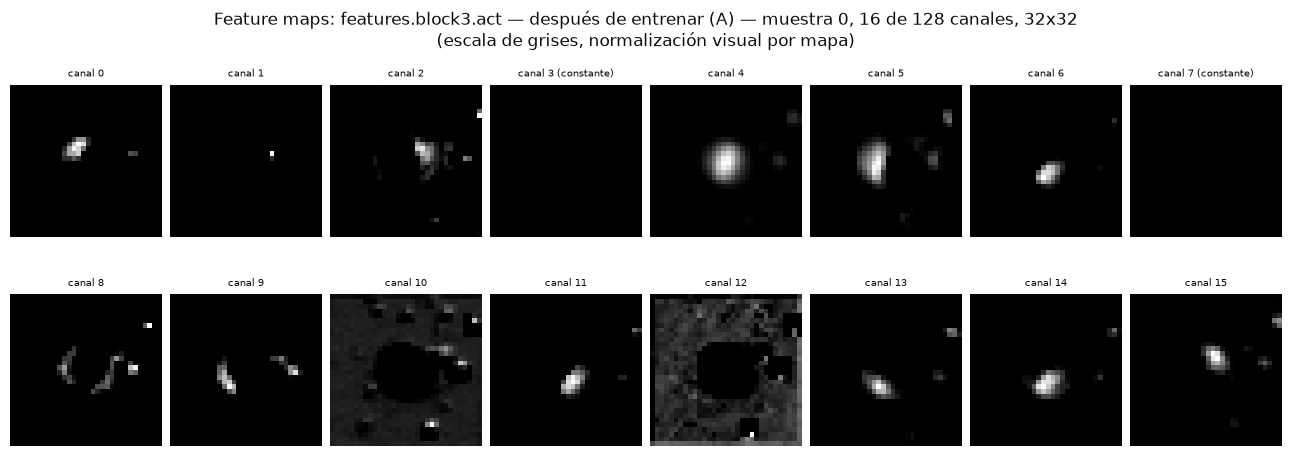

In [38]:
trained_a = best_models["baseline"]
maps_after = {
    layer: capture_feature_maps(trained_a, x_sample, layer, device) for layer in FM_LAYERS
}

for layer in FM_LAYERS:
    plot_feature_maps(maps_before[layer], layer_name=f"{layer} — antes de entrenar")
    plot_feature_maps(maps_after[layer], layer_name=f"{layer} — después de entrenar (A)")

In [39]:
def activation_summary(maps: torch.Tensor) -> dict[str, float]:
    per_channel_max = maps[0].amax(dim=(1, 2))
    return {
        "canales": maps.shape[1],
        "canales apagados (ReLU = 0 en todo el mapa)": int((per_channel_max == 0).sum()),
        "fracción de activaciones = 0": (maps == 0).float().mean().item(),
        "activación media": maps.mean().item(),
    }


pd.DataFrame(
    {
        f"{layer} — {moment}": activation_summary(maps[layer])
        for layer in FM_LAYERS
        for moment, maps in (("antes", maps_before), ("después", maps_after))
    }
).T.astype({"canales": int, "canales apagados (ReLU = 0 en todo el mapa)": int})

,canales,canales apagados (ReLU = 0 en todo el mapa),fracción de activaciones = 0,activación media
features.block1.act — antes,32,0,0.6188,0.1147
features.block1.act — después,32,0,0.5901,0.1160
features.block3.act — antes,128,5,0.5224,0.0260
features.block3.act — después,128,12,0.8986,0.0416


Qué mirar (sin asignar significado a canales concretos):

- ¿Cambió la **estructura** de los mapas? Con pesos aleatorios los mapas del bloque 1 se
  parecen a versiones filtradas de la imagen; después de entrenar, ¿los canales responden
  de forma más diversa (centro, bordes, fondo)?
- ¿Cambió la **dispersión** (fracción de ceros, canales apagados)? En el bloque 3 la
  representación es más abstracta y de menor resolución: cada posición resume una región
  amplia de la galaxia.
- Las figuras usan normalización visual **por mapa**: el brillo no se compara entre mapas
  ni entre antes y después; para eso está la tabla.

## 14. Cierre

Preguntas para completar con los resultados de los runs definitivos (`EPOCHS = 40`):

1. **A → B (BatchNorm):** ¿cambió la mejor época, la forma de las curvas o el macro F1 de
   validation? ¿Cambió el generalization gap?
2. **B → C (Dropout):** ¿cambió el sobreajuste después del mínimo de `val_loss`? ¿Hubo una
   mejora apreciable en validation, o la diferencia está dentro de unas pocas imágenes?
3. **Loss vs accuracy:** ¿aparece en B y C la misma sobreconfianza que en A?

**Límites de esta comparación:** una sola `train_seed` (las diferencias son descriptivas),
no es un diseño factorial completo (falta Dropout sin BN) y la selección por `val_loss`
favorece las probabilidades bien asignadas sobre la accuracy.

**Lo que queda:** con la configuración elegida en validation, se ejecuta **una sola vez**
`evaluate_on_test(checkpoint_path, config)`, que registra los resultados de test en el mismo
run de MLflow. Eso pertenece a la Fase 13 y no está en este notebook.